# Part A — Agent-Based Model of Pandemic Spread

This notebook implements the base **SIR agent-based model** on a bounded $20\times20$ grid. It simulates at least 20 independent realizations, summarizes uncertainty across runs, and visualizes both the epidemic curves and the spatial distribution of agents.

## Model schedule at each time step

1. **Movement:** each agent either takes one cardinal step or stays in place. Attempts to cross a boundary leave the agent in its current cell.
2. **Transmission:** a susceptible agent sharing a cell with one or more infected agents becomes infected with probability $p$.
3. **Recovery:** agents that were infected at the start of the transmission/recovery phase recover with probability $q$. Newly infected agents first become eligible for recovery on the following step.

All state changes within a phase are simultaneous. Time 0 is recorded before any movement, so a 300-step simulation contains 301 observations.

In [1]:
from dataclasses import dataclass, asdict
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.style.use("seaborn-v0_8-whitegrid")

# Integer encodings make the simulation compact and fast.
SUSCEPTIBLE, INFECTED, RECOVERED = 0, 1, 2
STATE_NAMES = np.array(["Susceptible", "Infected", "Recovered"])
STATE_COLORS = {
    SUSCEPTIBLE: "#3B82F6",
    INFECTED: "#EF4444",
    RECOVERED: "#10B981",
}


## 1. Parameters

Edit only the configuration cell below to explore different scenarios. With `mobility = 0.80`, each of up, down, left, right, and stay has probability 0.20 before boundary effects—exactly the five-choice random walk in the prompt. Lower mobility adds more stays; `mobility = 1.0` removes the intentional stay option, although blocked boundary moves still result in staying put.

In [2]:
@dataclass(frozen=True)
class ModelConfig:
    grid_size: int = 20
    initial_susceptible: int = 195
    initial_infected: int = 5
    initial_recovered: int = 0
    transmission_probability: float = 0.35  # p
    recovery_probability: float = 0.03      # q
    mobility: float = 0.80                  # probability of attempting a cardinal move
    time_steps: int = 300
    n_runs: int = 20                        # increase for smoother uncertainty bands
    seed: int = 500                         # fixed seed for reproducible results
    snapshot_times: tuple = (0, 25, 50, 100, 200, 300)

CONFIG = ModelConfig()

def validate_config(config):
    n_agents = (config.initial_susceptible + config.initial_infected
                + config.initial_recovered)
    if config.grid_size < 1:
        raise ValueError("grid_size must be at least 1.")
    if n_agents < 1:
        raise ValueError("The population must contain at least one agent.")
    if min(config.initial_susceptible, config.initial_infected,
           config.initial_recovered) < 0:
        raise ValueError("Initial state counts cannot be negative.")
    for name in ("transmission_probability", "recovery_probability", "mobility"):
        if not 0 <= getattr(config, name) <= 1:
            raise ValueError(f"{name} must lie between 0 and 1.")
    if config.time_steps < 0 or config.n_runs < 1:
        raise ValueError("time_steps must be nonnegative and n_runs must be positive.")
    if any(t < 0 or t > config.time_steps for t in config.snapshot_times):
        raise ValueError("Every snapshot time must be between 0 and time_steps.")
    return n_agents

N_AGENTS = validate_config(CONFIG)
pd.Series(asdict(CONFIG), name="value").to_frame().rename_axis("parameter")


,value
parameter,
grid_size,20
initial_susceptible,195
initial_infected,5
initial_recovered,0
transmission_probability,0.35
recovery_probability,0.03
mobility,0.8
time_steps,300
n_runs,20


## 2. Simulation engine

Agents are initialized independently at uniformly random cells, so multiple agents may occupy the same cell. The implementation keeps positions and states in NumPy arrays and uses a cell-level infected-count grid for efficient contact detection.

In [3]:
def initialize_population(config, rng):
    """Return random positions and a shuffled state vector."""
    n_agents = (config.initial_susceptible + config.initial_infected
                + config.initial_recovered)
    positions = rng.integers(0, config.grid_size, size=(n_agents, 2))
    states = np.concatenate([
        np.full(config.initial_susceptible, SUSCEPTIBLE, dtype=np.int8),
        np.full(config.initial_infected, INFECTED, dtype=np.int8),
        np.full(config.initial_recovered, RECOVERED, dtype=np.int8),
    ])
    rng.shuffle(states)
    return positions, states


def move_agents(positions, config, rng):
    """Perform one bounded random-walk update in place."""
    directions = np.array([[-1, 0], [1, 0], [0, -1], [0, 1]], dtype=int)
    moving = rng.random(len(positions)) < config.mobility
    proposed = positions.copy()
    proposed[moving] += directions[rng.integers(0, 4, size=moving.sum())]

    # A move that would leave the grid is rejected, so the agent stays in place.
    valid = ((proposed >= 0) & (proposed < config.grid_size)).all(axis=1)
    positions[valid] = proposed[valid]


def update_health_states(positions, states, config, rng):
    """Apply simultaneous transmission, followed by recovery of prior infectives."""
    infected_before_update = states == INFECTED

    infected_by_cell = np.zeros((config.grid_size, config.grid_size), dtype=int)
    infected_positions = positions[infected_before_update]
    if len(infected_positions):
        np.add.at(infected_by_cell,
                  (infected_positions[:, 0], infected_positions[:, 1]), 1)

    exposed = ((states == SUSCEPTIBLE)
               & (infected_by_cell[positions[:, 0], positions[:, 1]] > 0))
    newly_infected = exposed & (rng.random(len(states)) < config.transmission_probability)
    recovered_now = (infected_before_update
                     & (rng.random(len(states)) < config.recovery_probability))

    states[newly_infected] = INFECTED
    states[recovered_now] = RECOVERED


def state_counts(states):
    return np.bincount(states, minlength=3)


def simulate(config, rng, keep_snapshots=False):
    """Run one realization and return S/I/R history plus optional snapshots."""
    positions, states = initialize_population(config, rng)
    history = np.empty((config.time_steps + 1, 3), dtype=int)
    history[0] = state_counts(states)

    requested = set(config.snapshot_times) if keep_snapshots else set()
    snapshots = {}
    if 0 in requested:
        snapshots[0] = (positions.copy(), states.copy())

    for step in range(1, config.time_steps + 1):
        move_agents(positions, config, rng)
        update_health_states(positions, states, config, rng)
        history[step] = state_counts(states)
        if step in requested:
            snapshots[step] = (positions.copy(), states.copy())

    return history, snapshots


## 3. Run the ensemble

`SeedSequence.spawn` gives every realization an independent, reproducible random stream. Spatial snapshots are retained for the first run; all runs contribute to the aggregate trends.

In [4]:
seed_sequence = np.random.SeedSequence(CONFIG.seed)
run_seeds = seed_sequence.spawn(CONFIG.n_runs)
all_histories = np.empty((CONFIG.n_runs, CONFIG.time_steps + 1, 3), dtype=int)
example_snapshots = {}

start = perf_counter()
for run_id, child_seed in enumerate(run_seeds):
    run_rng = np.random.default_rng(child_seed)
    history, snapshots = simulate(CONFIG, run_rng, keep_snapshots=(run_id == 0))
    all_histories[run_id] = history
    if run_id == 0:
        example_snapshots = snapshots
elapsed = perf_counter() - start

# Model invariants: population is conserved and recovered counts never decrease.
assert np.all(all_histories.sum(axis=2) == N_AGENTS)
assert np.all(np.diff(all_histories[:, :, RECOVERED], axis=1) >= 0)
assert tuple(all_histories[0, 0]) == (CONFIG.initial_susceptible,
                                             CONFIG.initial_infected,
                                             CONFIG.initial_recovered)

print(f"Completed {CONFIG.n_runs} runs × {CONFIG.time_steps} steps in {elapsed:.2f} seconds.")
print("Population-conservation and state-transition checks passed.")


Completed 20 runs × 300 steps in 0.21 seconds.
Population-conservation and state-transition checks passed.


In [5]:
# Compact run-level summary for comparing stochastic outcomes.
summary = pd.DataFrame({
    "run": np.arange(1, CONFIG.n_runs + 1),
    "peak_infected": all_histories[:, :, INFECTED].max(axis=1),
    "peak_time": all_histories[:, :, INFECTED].argmax(axis=1),
    "final_susceptible": all_histories[:, -1, SUSCEPTIBLE],
    "final_infected": all_histories[:, -1, INFECTED],
    "final_recovered": all_histories[:, -1, RECOVERED],
})

display(summary)
display(summary.drop(columns="run").describe().round(1))


,run,peak_infected,peak_time,final_susceptible,final_infected,final_recovered
0,1,74,60,7,0,193
1,2,84,60,7,0,193
2,3,39,78,19,1,180
3,4,78,62,8,0,192
4,5,76,59,9,0,191
5,6,91,48,9,1,190
6,7,53,62,17,2,181
7,8,55,87,13,0,187
8,9,54,76,3,0,197
9,10,87,56,3,0,197


,peak_infected,peak_time,final_susceptible,final_infected,final_recovered
count,20.0,20.0,20.0,20.0,20.0
mean,71.8,60.7,7.6,0.4,192.0
std,14.0,12.9,4.8,0.6,5.0
min,39.0,37.0,0.0,0.0,180.0
25%,61.8,54.0,5.2,0.0,190.8
50%,76.0,60.0,7.5,0.0,192.0
75%,81.0,67.2,9.0,1.0,194.8
max,91.0,87.0,19.0,2.0,199.0


## 4. Epidemic trends across runs

Thin lines show individual stochastic realizations. Thick lines show the ensemble mean, and shaded bands span the 2.5th–97.5th percentiles across runs.

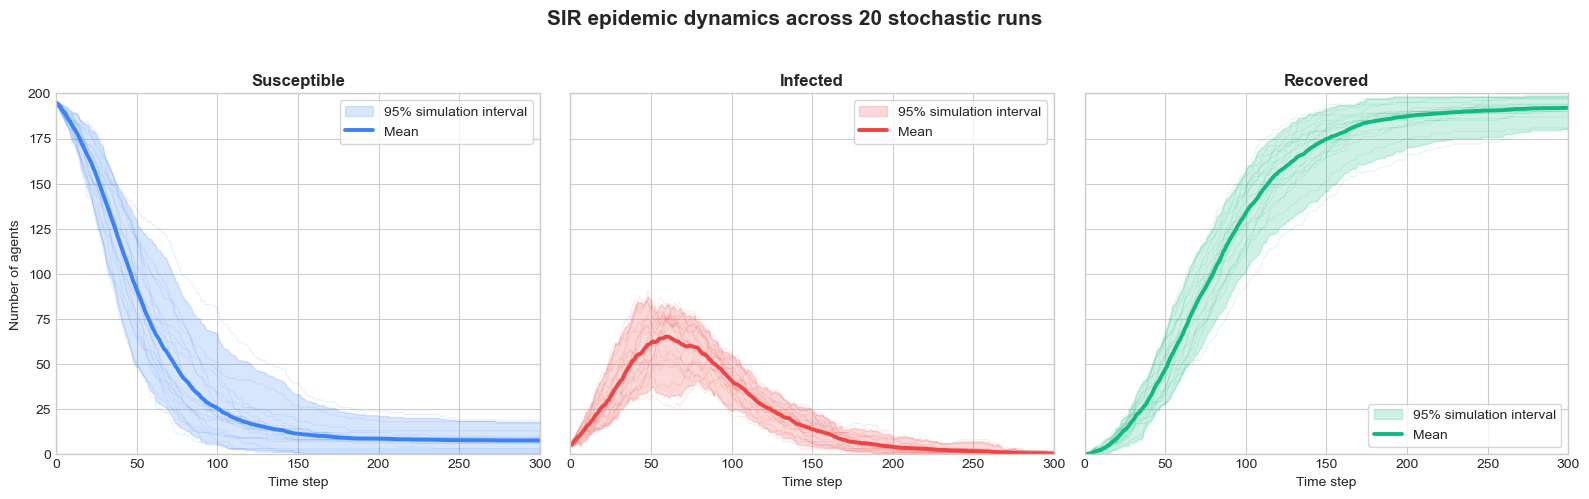

In [6]:
times = np.arange(CONFIG.time_steps + 1)
mean_history = all_histories.mean(axis=0)
lower, upper = np.quantile(all_histories, [0.025, 0.975], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for state, ax in enumerate(axes):
    color = STATE_COLORS[state]
    ax.plot(times, all_histories[:, :, state].T, color=color, alpha=0.12, lw=0.8)
    ax.fill_between(times, lower[:, state], upper[:, state], color=color, alpha=0.20,
                    label="95% simulation interval")
    ax.plot(times, mean_history[:, state], color=color, lw=2.8, label="Mean")
    ax.set_title(STATE_NAMES[state], weight="bold")
    ax.set_xlabel("Time step")
    ax.set_xlim(0, CONFIG.time_steps)
    ax.set_ylim(0, N_AGENTS)
    ax.legend(frameon=True, loc="best")
axes[0].set_ylabel("Number of agents")
fig.suptitle(f"SIR epidemic dynamics across {CONFIG.n_runs} stochastic runs",
             fontsize=15, weight="bold", y=1.03)
fig.tight_layout()
plt.show()


## 5. Spatial snapshots from one representative run

Each dot is one agent. A small plotting-only jitter reveals agents that share a cell; it does not alter their simulated positions. Grid row 0 appears at the top, like a matrix. Counts in each title provide a direct link between the spatial and time-series views.

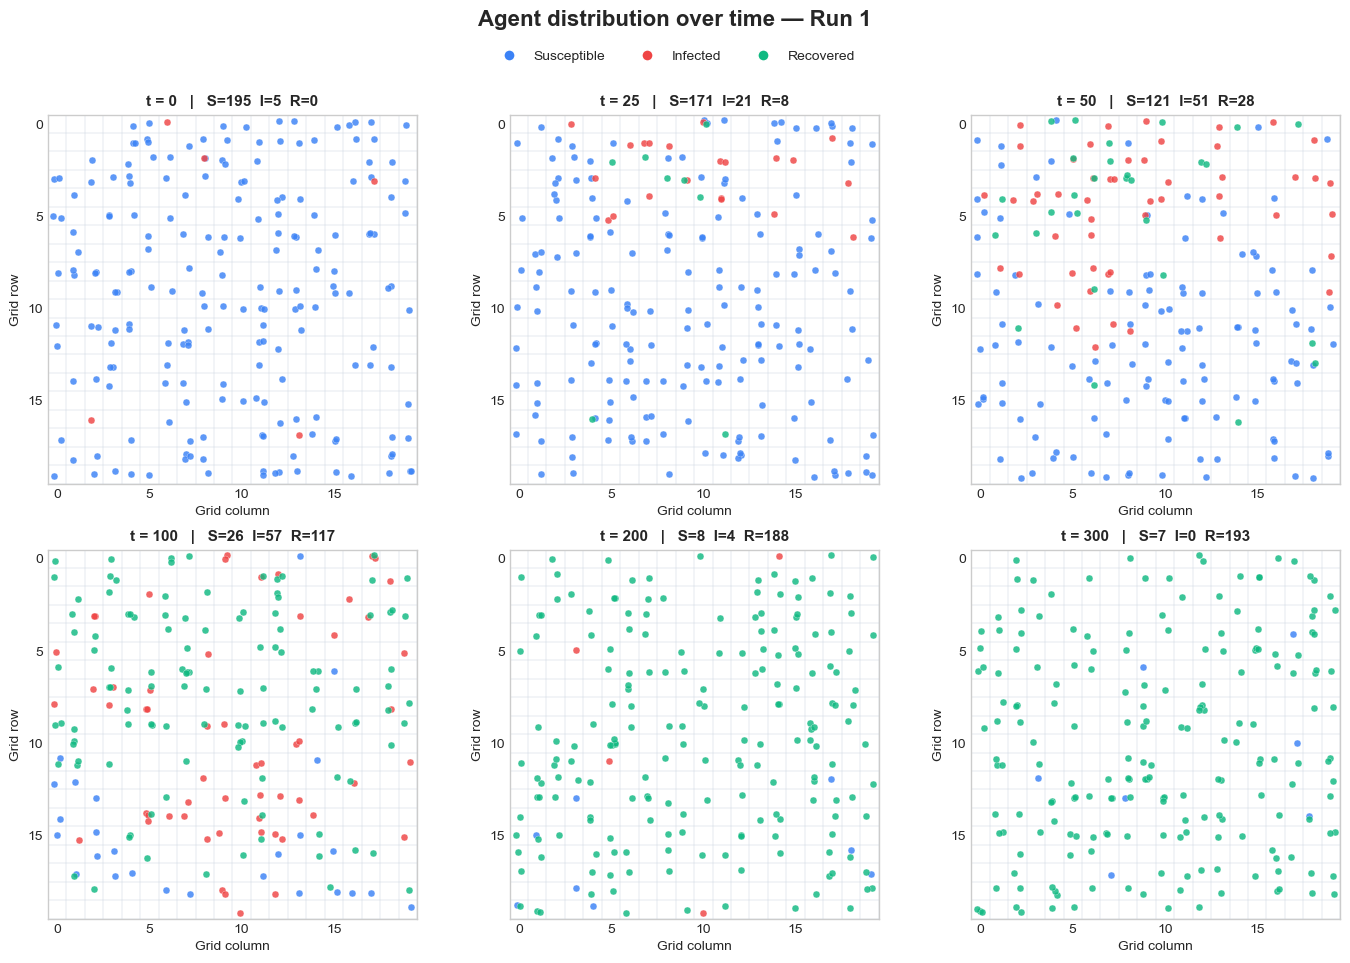

In [7]:
snapshot_times = sorted(example_snapshots)
ncols = 3
nrows = int(np.ceil(len(snapshot_times) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.6 * nrows), squeeze=False)
plot_rng = np.random.default_rng(CONFIG.seed + 1)  # affects only display jitter

for ax, step in zip(axes.flat, snapshot_times):
    positions, states = example_snapshots[step]
    jitter = plot_rng.uniform(-0.22, 0.22, size=positions.shape)
    for state in (SUSCEPTIBLE, INFECTED, RECOVERED):
        mask = states == state
        ax.scatter(positions[mask, 1] + jitter[mask, 1],
                   positions[mask, 0] + jitter[mask, 0],
                   s=25, c=STATE_COLORS[state], alpha=0.82,
                   edgecolors="white", linewidths=0.25)
    counts = state_counts(states)
    ax.set_title(f"t = {step}   |   S={counts[0]}  I={counts[1]}  R={counts[2]}",
                 fontsize=11, weight="bold")
    ax.set_xlim(-0.5, CONFIG.grid_size - 0.5)
    ax.set_ylim(CONFIG.grid_size - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(-0.5, CONFIG.grid_size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, CONFIG.grid_size, 1), minor=True)
    ax.grid(which="minor", color="#CBD5E1", linewidth=0.35)
    ax.grid(which="major", visible=False)
    ax.set_xticks(np.arange(0, CONFIG.grid_size, 5))
    ax.set_yticks(np.arange(0, CONFIG.grid_size, 5))
    ax.set_xlabel("Grid column")
    ax.set_ylabel("Grid row")

for ax in axes.flat[len(snapshot_times):]:
    ax.set_visible(False)

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=STATE_COLORS[s],
           markeredgecolor="white", markersize=8, label=STATE_NAMES[s])
    for s in (SUSCEPTIBLE, INFECTED, RECOVERED)
]
fig.legend(handles=legend_handles, loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Agent distribution over time — Run 1",
             fontsize=16, weight="bold", y=1.04)
fig.tight_layout()
plt.show()


## 6. Ccompare final outbreak sizes

The recovered count at the end of a run is the cumulative number ever infected, including the five initially infected agents if they have recovered. The plot below highlights run-to-run variability.

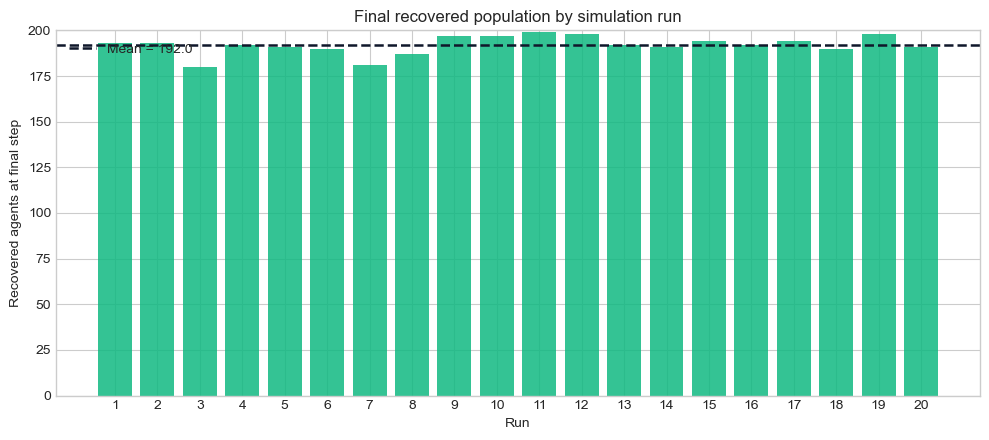

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(summary["run"], summary["final_recovered"],
              color=STATE_COLORS[RECOVERED], alpha=0.85)
ax.axhline(summary["final_recovered"].mean(), color="#0F172A", ls="--", lw=1.8,
           label=f"Mean = {summary['final_recovered'].mean():.1f}")
ax.set(title="Final recovered population by simulation run",
       xlabel="Run", ylabel="Recovered agents at final step")
ax.set_xticks(summary["run"])
ax.set_ylim(0, N_AGENTS)
ax.legend()
fig.tight_layout()
plt.show()


## 7. Head-to-head comparison of transmission and recovery rates

This factorial experiment compares all four combinations of $p\in\{0.15, 0.30\}$ and $q\in\{0.02, 0.04\}$. Every scenario uses the same grid, initial conditions, mobility, 300-step horizon, and number of runs defined in `CONFIG`. Independent child random-number streams make the comparison reproducible without reusing the exact same simulation randomness.

In [9]:
parameter_pairs = [(0.15, 0.02), (0.15, 0.04), (0.30, 0.02), (0.30, 0.04)]
scenario_configs = {
    (p, q): ModelConfig(**{
        **asdict(CONFIG),
        "transmission_probability": p,
        "recovery_probability": q,
    })
    for p, q in parameter_pairs
}

comparison_seed = np.random.SeedSequence(CONFIG.seed + 10_000)
comparison_seeds = iter(comparison_seed.spawn(len(parameter_pairs) * CONFIG.n_runs))
scenario_histories = {}

start = perf_counter()
for pair in parameter_pairs:
    config = scenario_configs[pair]
    histories = np.empty((config.n_runs, config.time_steps + 1, 3), dtype=int)
    for run_id in range(config.n_runs):
        histories[run_id], _ = simulate(
            config, np.random.default_rng(next(comparison_seeds)), keep_snapshots=False
        )
    scenario_histories[pair] = histories

assert all(np.all(h.sum(axis=2) == N_AGENTS) for h in scenario_histories.values())
comparison_elapsed = perf_counter() - start
print(
    f"Completed {len(parameter_pairs)} scenarios × {CONFIG.n_runs} runs "
    f"× {CONFIG.time_steps} steps in {comparison_elapsed:.2f} seconds."
)


Completed 4 scenarios × 20 runs × 300 steps in 0.96 seconds.


### Individual trajectories and scenario averages

Each faint line is one run; each thick line is the average across runs. The parameter values are printed inside every panel.

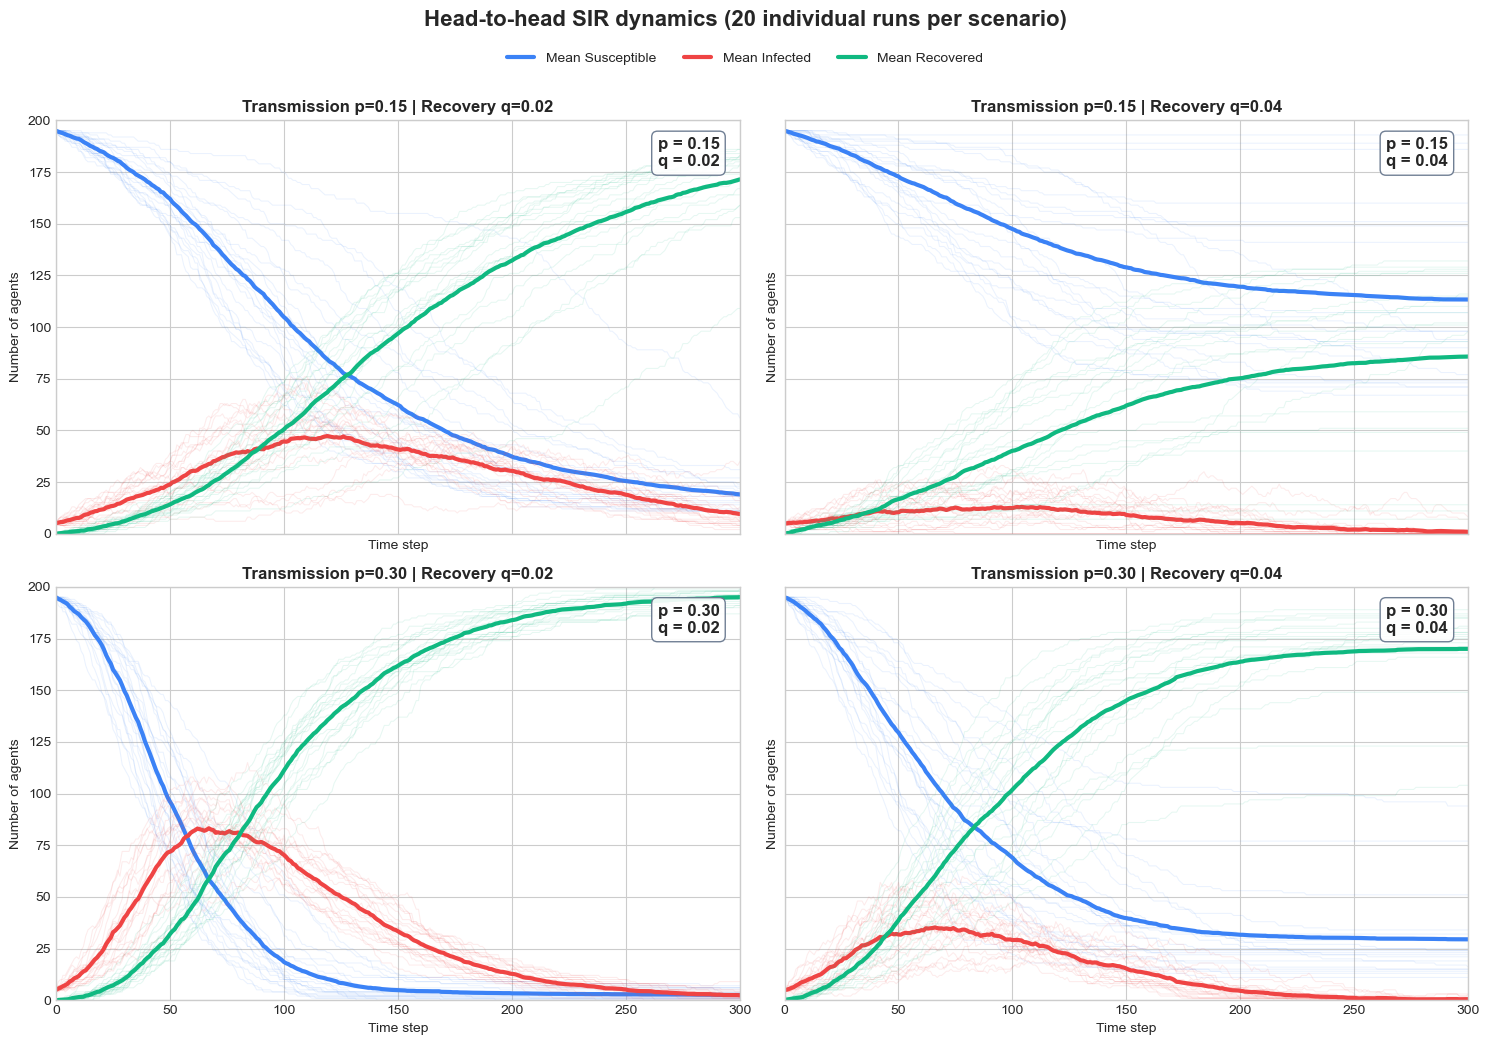

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
times = np.arange(CONFIG.time_steps + 1)

for ax, (p, q) in zip(axes.flat, parameter_pairs):
    histories = scenario_histories[(p, q)]
    for state in (SUSCEPTIBLE, INFECTED, RECOVERED):
        color = STATE_COLORS[state]
        ax.plot(times, histories[:, :, state].T, color=color, alpha=0.10, lw=0.75)
        ax.plot(times, histories[:, :, state].mean(axis=0), color=color, lw=3.0,
                label=f"Mean {STATE_NAMES[state]}")

    ax.text(0.97, 0.96, f"p = {p:.2f}\nq = {q:.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=12, weight="bold",
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                      edgecolor="#64748B", alpha=0.92))
    ax.set_title(f"Transmission p={p:.2f} | Recovery q={q:.2f}", weight="bold")
    ax.set_xlim(0, CONFIG.time_steps)
    ax.set_ylim(0, N_AGENTS)
    ax.set_xlabel("Time step")
    ax.set_ylabel("Number of agents")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.01))
fig.suptitle(
    f"Head-to-head SIR dynamics ({CONFIG.n_runs} individual runs per scenario)",
    fontsize=16, weight="bold", y=1.04
)
fig.tight_layout()
plt.show()


### Peak strength, peak timing, and epidemic duration

For each run:

- **Peak strength** is the largest number of simultaneously infected agents.
- **Peak timing** is the first time step at which that maximum occurs.
- **Epidemic duration** is the first time step with zero infected agents. A run that still has infected agents at step 300 is right-censored and is plotted at 300 rather than treated as an observed extinction time.

The table reports mean ± standard deviation and median [interquartile range] across individual runs.

In [11]:
metric_frames = []
for p, q in parameter_pairs:
    histories = scenario_histories[(p, q)]
    infected = histories[:, :, INFECTED]
    reaches_zero = (infected == 0).any(axis=1)
    first_zero = (infected == 0).argmax(axis=1)
    duration = np.where(reaches_zero, first_zero, CONFIG.time_steps)

    metric_frames.append(pd.DataFrame({
        "p": p,
        "q": q,
        "scenario": f"p={p:.2f}, q={q:.2f}",
        "run": np.arange(1, CONFIG.n_runs + 1),
        "peak_strength": infected.max(axis=1),
        "peak_timing": infected.argmax(axis=1),
        "duration": duration,
        "right_censored": ~reaches_zero,
    }))

run_metrics = pd.concat(metric_frames, ignore_index=True)

def mean_sd(values):
    return f"{values.mean():.1f} ± {values.std(ddof=1):.1f}"

def median_iqr(values):
    q1, median, q3 = values.quantile([0.25, 0.50, 0.75])
    return f"{median:.1f} [{q1:.1f}, {q3:.1f}]"

report_rows = []
for (p, q), group in run_metrics.groupby(["p", "q"], sort=False):
    report_rows.append({
        "p": p,
        "q": q,
        "Peak strength — mean ± SD": mean_sd(group["peak_strength"]),
        "Peak strength — median [IQR]": median_iqr(group["peak_strength"]),
        "Peak timing — mean ± SD": mean_sd(group["peak_timing"]),
        "Peak timing — median [IQR]": median_iqr(group["peak_timing"]),
        "Duration — mean ± SD": mean_sd(group["duration"]),
        "Duration — median [IQR]": median_iqr(group["duration"]),
        f"Still active at t={CONFIG.time_steps}": (
            f"{group['right_censored'].sum()} / {len(group)}"
        ),
    })

distribution_report = pd.DataFrame(report_rows)
display(distribution_report.style.hide(axis="index"))


p,q,Peak strength — mean ± SD,Peak strength — median [IQR],Peak timing — mean ± SD,Peak timing — median [IQR],Duration — mean ± SD,Duration — median [IQR],Still active at t=300
0.150000,0.020000,56.6 ± 11.6,"58.0 [47.5, 63.0]",125.5 ± 42.6,"116.0 [102.0, 130.0]",300.0 ± 0.0,"300.0 [300.0, 300.0]",20 / 20
0.150000,0.040000,20.1 ± 8.9,"22.5 [10.8, 26.0]",84.8 ± 63.2,"75.5 [43.2, 110.0]",227.3 ± 84.3,"249.0 [212.0, 288.8]",5 / 20
0.300000,0.020000,91.5 ± 13.1,"93.5 [83.8, 98.5]",70.8 ± 16.9,"62.5 [59.0, 81.5]",292.9 ± 17.9,"300.0 [300.0, 300.0]",17 / 20
0.300000,0.040000,45.1 ± 10.8,"44.0 [38.5, 53.0]",77.7 ± 32.1,"67.0 [49.5, 99.5]",254.8 ± 32.7,"245.0 [229.5, 289.5]",5 / 20


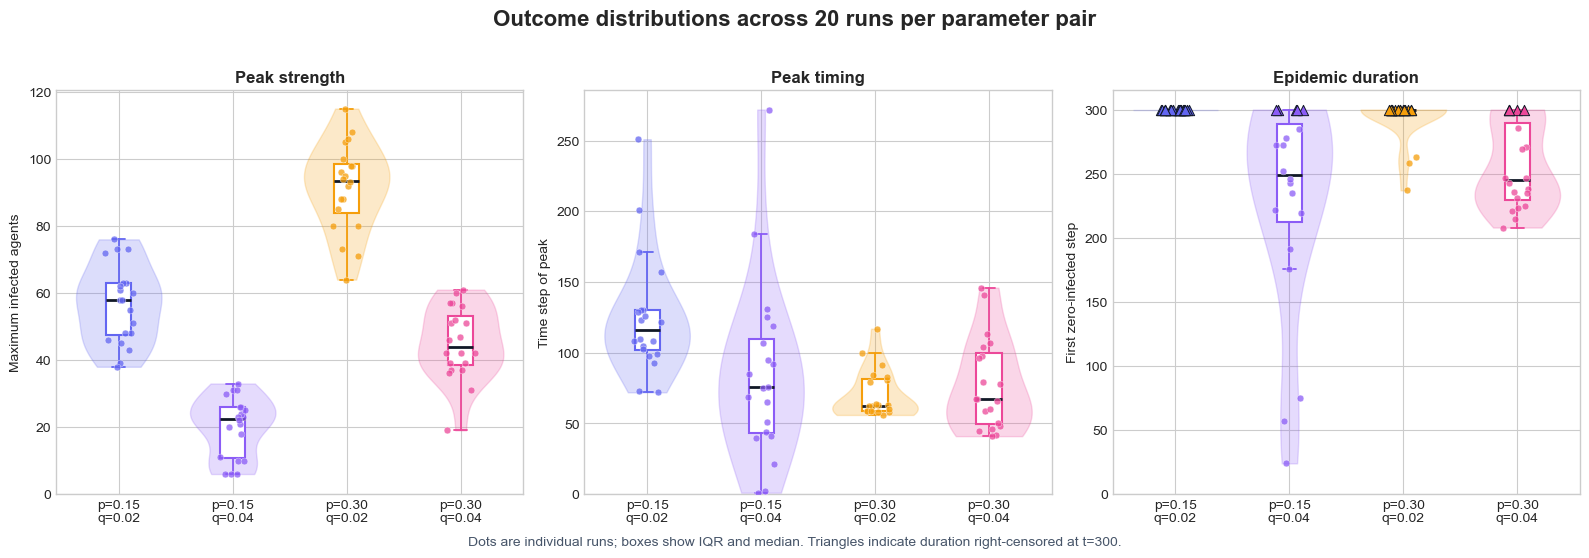

In [12]:
metric_specs = [
    ("peak_strength", "Peak strength", "Maximum infected agents"),
    ("peak_timing", "Peak timing", "Time step of peak"),
    ("duration", "Epidemic duration", "First zero-infected step"),
]
scenario_labels = [f"p={p:.2f}\nq={q:.2f}" for p, q in parameter_pairs]
scenario_colors = ["#6366F1", "#8B5CF6", "#F59E0B", "#EC4899"]
distribution_rng = np.random.default_rng(CONFIG.seed + 20_000)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, (column, title, ylabel) in zip(axes, metric_specs):
    for x, ((p, q), color) in enumerate(zip(parameter_pairs, scenario_colors), start=1):
        group = run_metrics[(run_metrics["p"] == p) & (run_metrics["q"] == q)]
        values = group[column].to_numpy()

        violin = ax.violinplot(values, positions=[x], widths=0.75,
                               showmeans=False, showmedians=False, showextrema=False)
        for body in violin["bodies"]:
            body.set_facecolor(color)
            body.set_edgecolor(color)
            body.set_alpha(0.22)

        ax.boxplot(values, positions=[x], widths=0.22, patch_artist=True,
                   showfliers=False,
                   boxprops=dict(facecolor="white", edgecolor=color, linewidth=1.5),
                   medianprops=dict(color="#111827", linewidth=2),
                   whiskerprops=dict(color=color, linewidth=1.3),
                   capprops=dict(color=color, linewidth=1.3))

        jitter_x = x + distribution_rng.uniform(-0.13, 0.13, size=len(group))
        observed = ~group["right_censored"].to_numpy() if column == "duration" else np.ones(len(group), dtype=bool)
        ax.scatter(jitter_x[observed], values[observed], s=24, color=color,
                   alpha=0.75, edgecolors="white", linewidths=0.35, zorder=3)
        if column == "duration" and (~observed).any():
            ax.scatter(jitter_x[~observed], values[~observed], s=55, marker="^",
                       color=color, edgecolors="#111827", linewidths=0.7, zorder=4)

    ax.set_title(title, weight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, len(parameter_pairs) + 1), scenario_labels)
    ax.set_xlim(0.45, len(parameter_pairs) + 0.55)

axes[0].set_ylim(bottom=0)
axes[1].set_ylim(bottom=0)
axes[2].set_ylim(0, CONFIG.time_steps * 1.05)
fig.suptitle(f"Outcome distributions across {CONFIG.n_runs} runs per parameter pair",
             fontsize=16, weight="bold", y=1.02)
fig.text(0.5, -0.01,
         f"Dots are individual runs; boxes show IQR and median. Triangles indicate duration right-censored at t={CONFIG.time_steps}.",
         ha="center", fontsize=10, color="#475569")
fig.tight_layout()
plt.show()
